# Experimento: NeuroLKH no TSP

Este notebook executa o `NeuroLKH` em 50 pesos de escalarização na instância TSP do projeto e explora os custos e a fronteira de Pareto amostrada. Cada chamada normaliza tempo e distância, unifica as duas matrizes com um peso, simetriza esse custo com Jonker-Volgenant e resolve o TSP simétrico de 2n nós com a rede pré-treinada e o LKH. A rota devolvida é a das n cidades originais; tempo e distância são somados nas matrizes originais. A heurística não garante uma solução ótima. A fronteira mostrada é apenas a das rotas geradas por esses pesos, não a fronteira ótima. O modelo não representa coordenadas geográficas, então o gráfico de rota mostra somente a sequência de cidades.

A implementação reutilizável está em `src/monoobjective_algorithms/tsp/heuristics/neuro_lkh.py`. O solver não aceita limites em objetivos secundários.


In [1]:
from pathlib import Path
from io import BytesIO
import csv
import sys

import matplotlib.pyplot as plt
from IPython.display import Image, display


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data/instances/tempo.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Não encontrei data/instances/tempo.csv. Abra o notebook dentro do workspace do projeto."
    )


REPOSITORY_ROOT = find_repository_root(Path.cwd().resolve())
SRC_PATH = str(REPOSITORY_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from monoobjective_algorithms.interfaces import SolveRequest
from monoobjective_algorithms.tsp.heuristics import NeuroLKH
from multiobjective_algorithms import non_dominated_mask
from optimization_problems.tsp import TSPInstance

print(f"Repositório: {REPOSITORY_ROOT}")


Repositório: /home/matheuscascalho/OtimizacaoMultiObjetivo


## Configure e carregue a instância

Use a mesma semente para reproduzir as mesmas rotas. Os CSVs são matrizes numéricas sem cabeçalho; o leitor abaixo mantém essa convenção. Com mais de uma amostra, os pesos cobrem o intervalo `[0, 1]`. Um peso fixo repetiria a mesma rota, porque o solver é determinístico. `LKH_TRIALS` fica abaixo do padrão 1000 da classe para as 50 chamadas terminarem nesta sessão.


In [2]:
SEED = 42
SOLUTION_COUNT = 50
LKH_TRIALS = 20
OBJECTIVE = "time"  # Objetivo principal: "time" ou "distance".
INSTANCE_DIRECTORY = REPOSITORY_ROOT / "data/instances"


def read_matrix(path: Path) -> list[list[float]]:
    with path.open(newline="", encoding="utf-8-sig") as file:
        return [[float(value) for value in row] for row in csv.reader(file)]


def scalarization_weights(count: int) -> list[float]:
    if count == 1:
        return [0.5]
    return [index / (count - 1) for index in range(count)]


instance = TSPInstance(
    time_matrix=read_matrix(INSTANCE_DIRECTORY / "tempo.csv"),
    distance_matrix=read_matrix(INSTANCE_DIRECTORY / "distancia.csv"),
)
weights = scalarization_weights(SOLUTION_COUNT)

print(f"Número de cidades: {instance.node_count}")
print(f"Pesos: {weights[0]:.2f} ... {weights[-1]:.2f} ({len(weights)} valores)")


Número de cidades: 250
Pesos: 0.00 ... 1.00 (50 valores)


## Execute e valide a solução

Gere uma rota para cada peso, com a mesma semente e o mesmo número de tentativas do LKH. Ambos os objetivos são minimizados; uma solução é não dominada se nenhuma outra amostrada for pelo menos tão boa nos dois objetivos e estritamente melhor em pelo menos um.


In [ ]:
solver = NeuroLKH(seed=SEED, lkh_trials=LKH_TRIALS)
results = []
for weight in weights:
    result = solver.solve(
        instance,
        SolveRequest(
            objective=OBJECTIVE,
            parameters={"weight": weight, "seed": SEED, "lkh_trials": LKH_TRIALS},
        ),
    )
    results.append(result)
    if len(results) == 1 or len(results) % 10 == 0 or len(results) == len(weights):
        print(f"Amostras concluídas: {len(results)}/{len(weights)}")

for candidate in results:
    candidate_route = candidate.solution.route
    assert candidate.status == "feasible"
    assert len(candidate_route) == instance.node_count + 1
    assert candidate_route[0] == candidate_route[-1] == 1
    assert set(candidate_route[:-1]) == set(range(1, instance.node_count + 1))

objective_points = [
    (candidate.objective_values["time"], candidate.objective_values["distance"])
    for candidate in results
]
is_non_dominated = non_dominated_mask(
    objective_points,
    directions=("minimize", "minimize"),
)
result = results[0]
route = result.solution.route
unique_routes = {candidate.solution.route for candidate in results}

print(f"Soluções geradas: {len(results)}")
print(f"Rotas únicas: {len(unique_routes)}")
print(f"Soluções não dominadas na amostra: {sum(is_non_dominated)}")
print(f"Semente: {SEED}")
print(f"Tentativas do LKH: {LKH_TRIALS}")
print(f"Objetivo principal: {OBJECTIVE}")
print(f"Peso da primeira solução: {weights[0]:.2f}")
print(f"Rota da primeira solução (início/fim): {route[:10]} ... {route[-5:]}")
print(f"Tempo da primeira solução: {result.objective_values['time']:.2f} h")
print(f"Distância da primeira solução: {result.objective_values['distance']:.2f} km")


Amostras concluídas: 1/50
Amostras concluídas: 10/50
Amostras concluídas: 20/50
Amostras concluídas: 30/50
Amostras concluídas: 40/50


## Visualize a rota, os custos e a fronteira amostrada

O painel da rota mostra a primeira solução gerada, correspondente ao peso 0. O diagrama de dispersão mostra os 50 pares de objetivos: dominadas com `alpha=0.3` e não dominadas com `alpha=1`. As não dominadas são conectadas em ordem crescente de tempo. Como todos os objetivos são minimizados, os pontos conectados formam somente a fronteira de Pareto observada nesta amostra de pesos.


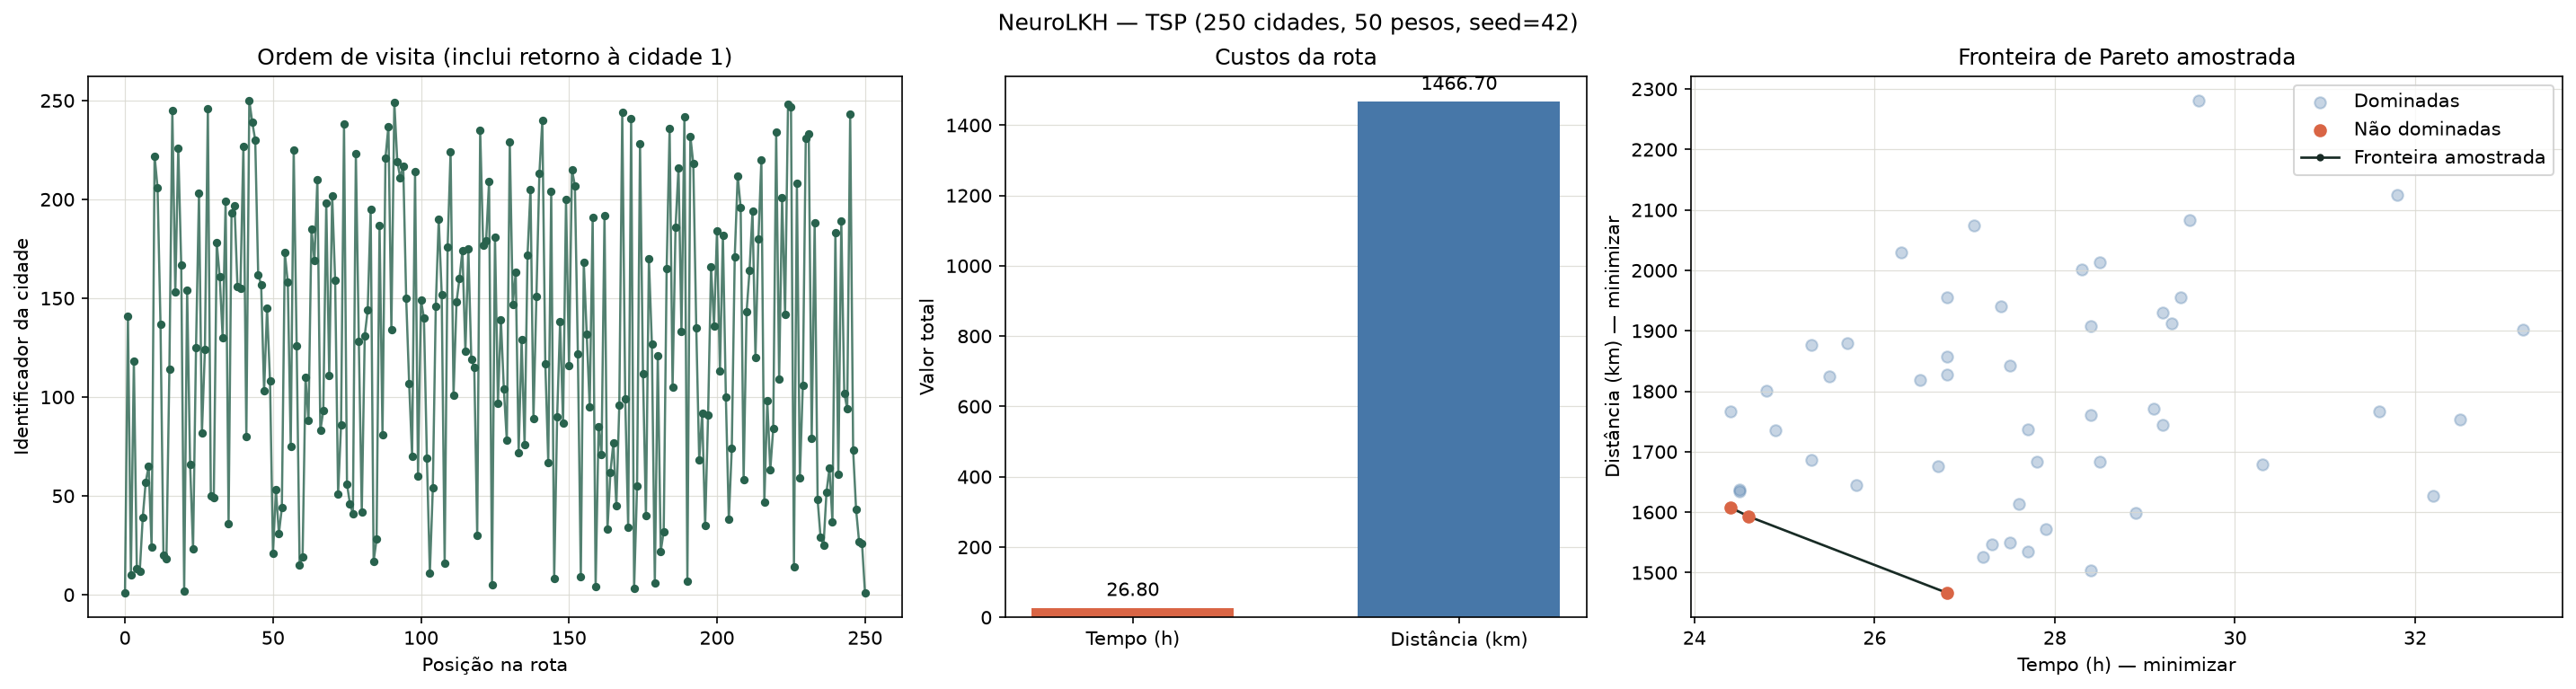

In [ ]:
visit_positions = list(range(len(route)))
objective_labels = ["Tempo (h)", "Distância (km)"]
objective_values = [
    result.objective_values["time"],
    result.objective_values["distance"],
]
objective_colors = ["#D96545", "#4777A8"]

fig, (route_ax, objective_ax, pareto_ax) = plt.subplots(
    1,
    3,
    figsize=(19, 5),
    gridspec_kw={"width_ratios": [1.4, 1, 1.5]},
    constrained_layout=True,
)

route_ax.plot(visit_positions, route, color="#28624D", linewidth=1.2, alpha=0.8)
route_ax.scatter(visit_positions, route, color="#28624D", s=12, zorder=2)
route_ax.set_title("Ordem de visita (inclui retorno à cidade 1)")
route_ax.set_xlabel("Posição na rota")
route_ax.set_ylabel("Identificador da cidade")
route_ax.grid(True, color="#D9D8D0", linewidth=0.6, alpha=0.8)

bars = objective_ax.bar(
    objective_labels,
    objective_values,
    color=objective_colors,
    width=0.62,
)
objective_ax.set_title("Custos da rota")
objective_ax.set_ylabel("Valor total")
objective_ax.grid(axis="y", color="#D9D8D0", linewidth=0.6, alpha=0.8)
objective_ax.set_axisbelow(True)
objective_ax.bar_label(bars, fmt="%.2f", padding=4)

dominated_points = [
    point for point, keep in zip(objective_points, is_non_dominated) if not keep
]
non_dominated_points = [
    point for point, keep in zip(objective_points, is_non_dominated) if keep
]
if dominated_points:
    pareto_ax.scatter(
        [point[0] for point in dominated_points],
        [point[1] for point in dominated_points],
        color="#4777A8",
        alpha=0.3,
        label="Dominadas",
    )

sorted_front = sorted(non_dominated_points, key=lambda point: (point[0], point[1]))
pareto_ax.scatter(
    [point[0] for point in non_dominated_points],
    [point[1] for point in non_dominated_points],
    color="#D96545",
    alpha=1,
    label="Não dominadas",
    zorder=3,
)
if len(sorted_front) > 1:
    pareto_ax.plot(
        [point[0] for point in sorted_front],
        [point[1] for point in sorted_front],
        color="#182B25",
        linewidth=1.3,
        marker="o",
        markersize=3,
        label="Fronteira amostrada",
        zorder=2,
    )
pareto_ax.set_title("Fronteira de Pareto amostrada")
pareto_ax.set_xlabel("Tempo (h) — minimizar")
pareto_ax.set_ylabel("Distância (km) — minimizar")
pareto_ax.grid(True, color="#D9D8D0", linewidth=0.6, alpha=0.8)
pareto_ax.legend()

fig.suptitle(
    f"NeuroLKH — TSP ({instance.node_count} cidades, {SOLUTION_COUNT} pesos, seed={SEED})"
)
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
display(Image(data=image_buffer.getvalue()))
plt.close(fig)
